# General Linear Model (GLM) Analysis

**NX-421 — Neural Signals and Signal Processing**

In this notebook, we analyze task-related brain activity in the Human Connectome Project (HCP) language-task fMRI dataset using the General Linear Model (GLM).

Building on the structural and functional preprocessing performed in the previous notebooks, we first construct an experimental design matrix representing the story, math, and cue conditions, together with motion-related nuisance regressors.

Following Lab 5, the task regressors are convolved with a canonical hemodynamic response function (HRF), and the design matrix is examined for correlations and potential multicollinearity.

We then fit a first-level GLM to the preprocessed functional data and evaluate statistical contrasts to identify regions associated with story comprehension and mathematical processing.

The statistical results are visualized using Nilearn, and multiple-comparison correction is applied when appropriate. All generated outputs are saved separately to support reproducibility.

## 0. Setup and Input Data

We first set up the Python environment and load the files required for the General Linear Model (GLM) analysis.

Following Lab 5, we use Nilearn to construct the experimental design matrix, fit the first-level GLM, compute statistical contrasts, and visualize the resulting activation maps.

The analysis builds on the outputs generated in the previous notebooks:

- **Structural preprocessing:** anatomical images registered to MNI152 space.
- **Functional preprocessing:** motion-corrected and Gaussian-smoothed fMRI data, together with MCFLIRT motion parameters.
- **Task events:** timing information for the story, math, and cue conditions.

We use the preprocessed functional run for GLM estimation and preserve the original dataset. All design matrices, statistical maps, and quality-control figures will be saved under `outputs/glm/`.

In [1]:
# General imports
import os
import inspect
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

# Nilearn: image processing and visualization
from nilearn import image, plotting
from nilearn.masking import compute_epi_mask
from nilearn.plotting import plot_design_matrix

# Nilearn: GLM design and estimation
from nilearn.glm.first_level import (
    make_first_level_design_matrix,
    FirstLevelModel
)
from nilearn.glm import threshold_stats_img

# Load FSL in Neurodesk, as in the previous notebooks
import module as lmod

await lmod.purge(force=True)
await lmod.load("fsl/6.0.7.18")

# Project directories
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
FUNC_DATA_DIR = DATA_DIR / "fMRI" / "tfMRI_LANGUAGE_LR"

FUNC_PREPROC_DIR = PROJECT_ROOT / "outputs" / "functional"
GLM_DIR = PROJECT_ROOT / "outputs" / "glm"
FIRST_LEVEL_DIR = GLM_DIR / "first_level"

GLM_DIR.mkdir(parents=True, exist_ok=True)
FIRST_LEVEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Functional preprocessing directory:", FUNC_PREPROC_DIR)
print("GLM output directory:", GLM_DIR)
print("First-level GLM directory:", FIRST_LEVEL_DIR)
print("FSLDIR:", os.environ.get("FSLDIR"))

Project directory: /data/Desktop/myfiles/NX421-MiniProject-1
Functional preprocessing directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/functional
GLM output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm
First-level GLM directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/first_level
FSLDIR: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18


### 0.1 Input Files

We use the following files:

- **From points 2a–b:** the motion-corrected fMRI run, its motion parameters (`.par` file from MCFLIRT), and the motion-corrected + smoothed run, on which the GLM will be fitted.
- **From the dataset:** the original functional run (used to verify the number of volumes and timing) and the task events (`tfMRI_LANGUAGE_LR_task_onsets.csv`).
- **From point 3a:** the experimental design matrix, which will be generated in the following sections and subsequently used for first-level GLM estimation.

The final preprocessed functional image and the design matrix must have the same number of time points. All files are checked before proceeding with the analysis.

In [2]:
# Points 2a-b: functional preprocessing
moco_fmri_path = FUNC_PREPROC_DIR / "tfMRI_LANGUAGE_LR_mcf.nii.gz"
motion_par_path = FUNC_PREPROC_DIR / "tfMRI_LANGUAGE_LR_mcf.par"
smoothed_fmri_path = FUNC_PREPROC_DIR / "tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz"

# Dataset
raw_fmri_path = FUNC_DATA_DIR / "tfMRI_LANGUAGE_LR.nii.gz"
events_path = FUNC_DATA_DIR / "tfMRI_LANGUAGE_LR_task_onsets.csv"

# Outputs used by the first-level GLM
DESIGN_MATRIX_PATH = GLM_DIR / "design_matrix.csv"
EVENTS_OUTPUT_PATH = GLM_DIR / "glm_events.csv"

# Verify all required input files
for path in [
    moco_fmri_path,
    motion_par_path,
    smoothed_fmri_path,
    raw_fmri_path,
    events_path
]:
    if not path.is_file():
        raise FileNotFoundError(f"Input not found: {path}")
    print(f"[OK] {path.name}")

print("\nFunctional image for GLM:", smoothed_fmri_path)
print("Design matrix will be saved to:", DESIGN_MATRIX_PATH)

[OK] tfMRI_LANGUAGE_LR_mcf.nii.gz
[OK] tfMRI_LANGUAGE_LR_mcf.par
[OK] tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
[OK] tfMRI_LANGUAGE_LR.nii.gz
[OK] tfMRI_LANGUAGE_LR_task_onsets.csv

Functional image for GLM: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/functional/tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz
Design matrix will be saved to: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/design_matrix.csv


## 1. Experimental Design Matrix (3a)

The goal of the GLM is to investigate the activation of the brain during the **math** and **story** tasks. The design matrix describes, for each volume of the run, the expected signal of each modelled process.

### 1.1 Functional Run Used for the GLM

The GLM will be fitted on the motion-corrected and smoothed run of point 2b. Its number of volumes and repetition time (TR) define the time axis of the design matrix.

In [3]:
fmri_img = nib.load(str(smoothed_fmri_path))

n_scans = fmri_img.shape[3]
t_r = float(fmri_img.header.get_zooms()[3])

# If volumes were removed at the start of the run in point 2a, the time axis starts later
n_removed = nib.load(str(raw_fmri_path)).shape[3] - n_scans

# Time of each volume (HCP uses multiband acquisition, so no slice-timing offset is applied)
frame_times = (np.arange(n_scans) + n_removed) * t_r

print("Number of volumes:", n_scans)
print("Volumes removed at the start of the run:", n_removed)
print(f"TR: {t_r:.2f} s")
print(f"Duration: {n_scans * t_r:.1f} s")

Number of volumes: 316
Volumes removed at the start of the run: 0
TR: 0.72 s
Duration: 227.5 s


### 1.2 Task Events

The timing of the task is given in `tfMRI_LANGUAGE_LR_task_onsets.csv`, with one row per event (onset and duration in seconds, and event type).

In [4]:
events_all = pd.read_csv(events_path)

print("Columns:", list(events_all.columns))
print(f"Number of events: {len(events_all)}\n")

# Number of events and durations for each event type
events_summary = (
    events_all.groupby("trial_type")["duration"]
    .agg(n_events="count", mean_duration_s="mean", total_duration_s="sum")
    .round(2)
)
events_summary

Columns: ['onset', 'duration', 'trial_type']
Number of events: 59



,n_events,mean_duration_s,total_duration_s
trial_type,,,
cue,7,0.77,5.38
math,9,12.08,108.72
present_math,9,5.46,49.14
present_story,4,20.03,80.11
question_math,9,3.45,31.09
question_story,4,1.16,4.64
response_math,9,2.96,26.66
response_story,4,2.96,11.84
story,4,27.70,110.79


The file contains two levels of description:

- **Block events:** `story` (4 blocks of 26–29 s) and `math` (9 blocks of about 12 s, each containing two to three arithmetic trials).
- **Sub-events nested inside the blocks:** the presentation of the stimulus (`present_story`, `present_math`), the question (`question_story`, `question_math`) and the response period (`response_story`, `response_math`).

In addition, short `cue` events (about 0.8 s) announce the beginning of each new block.

The timeline below shows how these events are organised during the run.

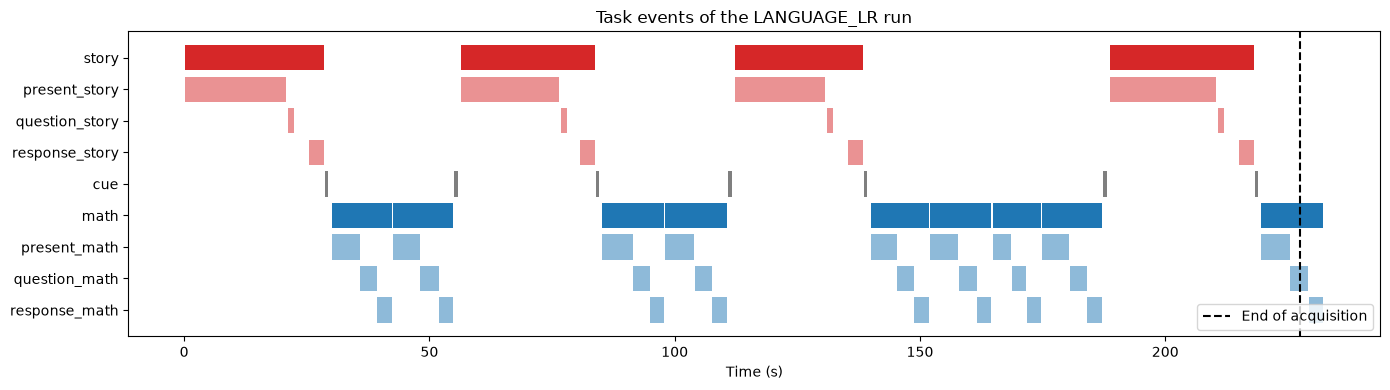

In [5]:
lanes = ["story", "present_story", "question_story", "response_story", "cue",
         "math", "present_math", "question_math", "response_math"]
colors = {"story": "tab:red", "math": "tab:blue", "cue": "tab:gray"}

fig, ax = plt.subplots(figsize=(14, 4))

for i, trial_type in enumerate(lanes):
    rows = events_all[events_all["trial_type"] == trial_type]
    color = colors.get(trial_type, "tab:red" if "story" in trial_type else "tab:blue")
    alpha = 1.0 if trial_type in colors else 0.5
    ax.broken_barh(list(zip(rows["onset"], rows["duration"])), (i - 0.4, 0.8),
                   facecolors=color, alpha=alpha)

ax.axvline(frame_times[-1] + t_r, color="black", linestyle="--", label="End of acquisition")
ax.set_yticks(range(len(lanes)))
ax.set_yticklabels(lanes)
ax.invert_yaxis()
ax.set_xlabel("Time (s)")
ax.set_title("Task events of the LANGUAGE_LR run")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(GLM_DIR / "fig_task_events_timeline.png",
            dpi=300, bbox_inches="tight")
plt.show()

### 1.3 Choice of the Task Regressors

We model the task at the **block level**, with one regressor for `story` and one for `math`. Block regressors capture the sustained activity during each task and give the most statistical power in a block design.

We also include the `cue` events as a third task regressor. The cues are a separate process (preparing for the next block), and modelling them prevents this activity from being absorbed into the story/math estimates.

We do **not** add the sub-events (`present_*`, `question_*`, `response_*`) to this model. They are nested inside the blocks and together cover the same time intervals, so their regressors would almost be a linear combination of the block regressors. The design matrix would then be nearly rank-deficient and the betas could not be estimated reliably.

All the time not covered by these events acts as the **implicit baseline** of the model. We measure how much baseline there is in this run.

In [6]:
TASK_CONDITIONS = ["story", "math", "cue"]

events = events_all[events_all["trial_type"].isin(TASK_CONDITIONS)]
events = events[["onset", "duration", "trial_type"]].sort_values("onset").reset_index(drop=True)
events.to_csv(GLM_DIR / "glm_events.csv", index=False)

# Time of the run not covered by any modelled event (implicit baseline), on a 10 ms grid
fine_times = np.arange(frame_times[0], frame_times[-1] + t_r, 0.01)
covered = np.zeros(fine_times.size, dtype=bool)

for onset, duration in zip(events["onset"], events["duration"]):
    covered |= (fine_times >= onset) & (fine_times < onset + duration)

baseline_s = (~covered).sum() * 0.01

print("Modelled events:", events["trial_type"].value_counts().to_dict())
print(f"Time covered by story/math/cue: {covered.mean() * 100:.1f} % of the run")
print(f"Implicit baseline: {baseline_s:.1f} s out of {fine_times.size * 0.01:.1f} s")

Modelled events: {'math': 9, 'cue': 7, 'story': 4}
Time covered by story/math/cue: 96.8 % of the run
Implicit baseline: 7.3 s out of 227.5 s


Almost the entire run is covered by the task events: there are only a few seconds of implicit baseline, spread over the short gaps between the cues and the blocks. This is an important property of this paradigm: **math is the control condition of story** (and vice versa), and there is no real rest period. We will see its consequences on the correlations between regressors (Section 2).

### 1.4 Confound Regressors

Following Lab 5, the design matrix also contains confound (no-interest) regressors:

- **The 6 rigid-body motion parameters** (3 rotations, 3 translations) estimated by MCFLIRT in point 2a, and their **temporal derivatives**. They model signal changes caused by head motion that remain after realignment.

- **One spike regressor per outlier volume.** Each spike regressor is 1 at one volume and 0 elsewhere, which accounts for that volume separately during model estimation without removing it from the time series (the timing of the design remains unchanged). We use them for:
  - Volumes with a framewise displacement (FD) above **0.5 mm**, with FD computed from the motion parameters as in Lab 3 (Power et al., 2012).
  - The **first two volumes (0 and 1)** of the run, whose global signal was approximately 1% and 0.5% higher than the rest of the run during functional quality control. These spike regressors were included as a precautionary modelling choice to account for initial signal fluctuations.

The initial volumes were retained during functional preprocessing. Their non-steady-state status was not independently established, so they are treated as potentially affected by initial signal instability rather than definitively identified non-steady-state volumes.

No volumes exceeded the FD threshold of 0.5 mm; therefore, no additional motion-outlier spike regressors were required.

In [7]:
FD_THRESHOLD = 0.5            # mm
NONSTEADY_VOLUMES = [0, 1]    # first volumes of the original run

MOTION_COLUMNS = ["Rotation x", "Rotation y", "Rotation z",
                  "Translation x", "Translation y", "Translation z"]


def load_mot_params_fsl_6_dof(path):
    # MCFLIRT .par file: 3 rotations (rad) followed by 3 translations (mm), one row per volume
    return pd.DataFrame(np.loadtxt(path), columns=MOTION_COLUMNS)


def compute_FD_power(mot_params):
    # Framewise displacement (Power et al. 2012), as in Lab 3
    framewise_diff = mot_params.diff().iloc[1:]
    # Rotations converted to displacements on a sphere of 50 mm radius
    converted_rots = framewise_diff[["Rotation x", "Rotation y", "Rotation z"]] * 50
    trans_params = framewise_diff[["Translation x", "Translation y", "Translation z"]]
    return converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)


mot_params = load_mot_params_fsl_6_dof(motion_par_path)

if len(mot_params) != n_scans:
    raise ValueError("The motion parameters do not match the number of volumes of the run.")

# FD of the first volume is set to 0
fd = np.concatenate([[0.0], compute_FD_power(mot_params).to_numpy()])
fd_outliers = np.where(fd > FD_THRESHOLD)[0].tolist()

# Non-steady-state volumes still present in the run (indices in the current run)
nonsteady = [v - n_removed for v in NONSTEADY_VOLUMES if v >= n_removed]

print(f"Mean FD: {fd.mean():.3f} mm, max FD: {fd.max():.3f} mm")
print(f"Volumes with FD > {FD_THRESHOLD} mm: {fd_outliers}")
print(f"Non-steady-state volumes still in the run: {nonsteady}")

Mean FD: 0.085 mm, max FD: 0.259 mm
Volumes with FD > 0.5 mm: []
Non-steady-state volumes still in the run: [0, 1]


### 1.5 Building the Design Matrix

The design matrix is built with `make_first_level_design_matrix`, as in Lab 5:

- **Task regressors:** each event is modelled as a boxcar (1 during the event, 0 otherwise) and **convolved with the canonical SPM haemodynamic response function (HRF)**, since the BOLD signal is a delayed and smoothed version of the neural activity.
- **Drift regressors:** a discrete cosine basis with a high-pass cut-off of 1/128 Hz models slow scanner drifts. A story + math cycle lasts about 40–55 s, well below the 128 s cut-off, so the task signal is not removed by the filter.
- **Confound regressors:** the motion parameters, their derivatives and the spike regressors defined above.
- **Constant:** the mean signal of each voxel.

In [8]:
HRF_MODEL = "spm"
HIGH_PASS = 1 / 128  # Hz

# Confound regressors: motion parameters (demeaned), their derivatives and spike regressors
confounds = pd.DataFrame(index=range(n_scans))

motion = mot_params.to_numpy()
motion_names = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]

for i, name in enumerate(motion_names):
    confounds[name] = motion[:, i] - motion[:, i].mean()
for i, name in enumerate(motion_names):
    confounds[name + "_deriv"] = np.concatenate([[0.0], np.diff(motion[:, i])])

spike_volumes = [(v, "nonsteady") for v in nonsteady]
spike_volumes += [(v, "fd_outlier") for v in fd_outliers if v not in nonsteady]

for volume, kind in spike_volumes:
    spike = np.zeros(n_scans)
    spike[volume] = 1.0
    confounds[f"{kind}_{volume}"] = spike

design_matrix = make_first_level_design_matrix(
    frame_times,
    events,
    hrf_model=HRF_MODEL,
    drift_model="cosine",
    high_pass=HIGH_PASS,
    add_regs=confounds.to_numpy(),
    add_reg_names=list(confounds.columns),
)

design_matrix.to_csv(GLM_DIR / "design_matrix.csv")

print("Design matrix shape (volumes x regressors):", design_matrix.shape)
print("Regressors:", list(design_matrix.columns))
print("Rank:", np.linalg.matrix_rank(design_matrix.to_numpy()))

Design matrix shape (volumes x regressors): (316, 21)
Regressors: ['cue', 'math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'rot_x_deriv', 'rot_y_deriv', 'rot_z_deriv', 'trans_x_deriv', 'trans_y_deriv', 'trans_z_deriv', 'nonsteady_0', 'nonsteady_1', 'drift_1', 'drift_2', 'drift_3', 'constant']
Rank: 21


### 1.6 Design Matrix Visualization

The resulting design matrix contains 316 time points and 21 regressors: three task regressors (`cue`, `math`, `story`), six motion parameters, six motion derivatives, two initial-volume spike regressors, three cosine drift regressors, and one constant.

The matrix has full column rank (21/21), allowing the model coefficients to be estimated without exact linear dependencies. We visualize the matrix to examine the temporal structure and relative contributions of the regressors.

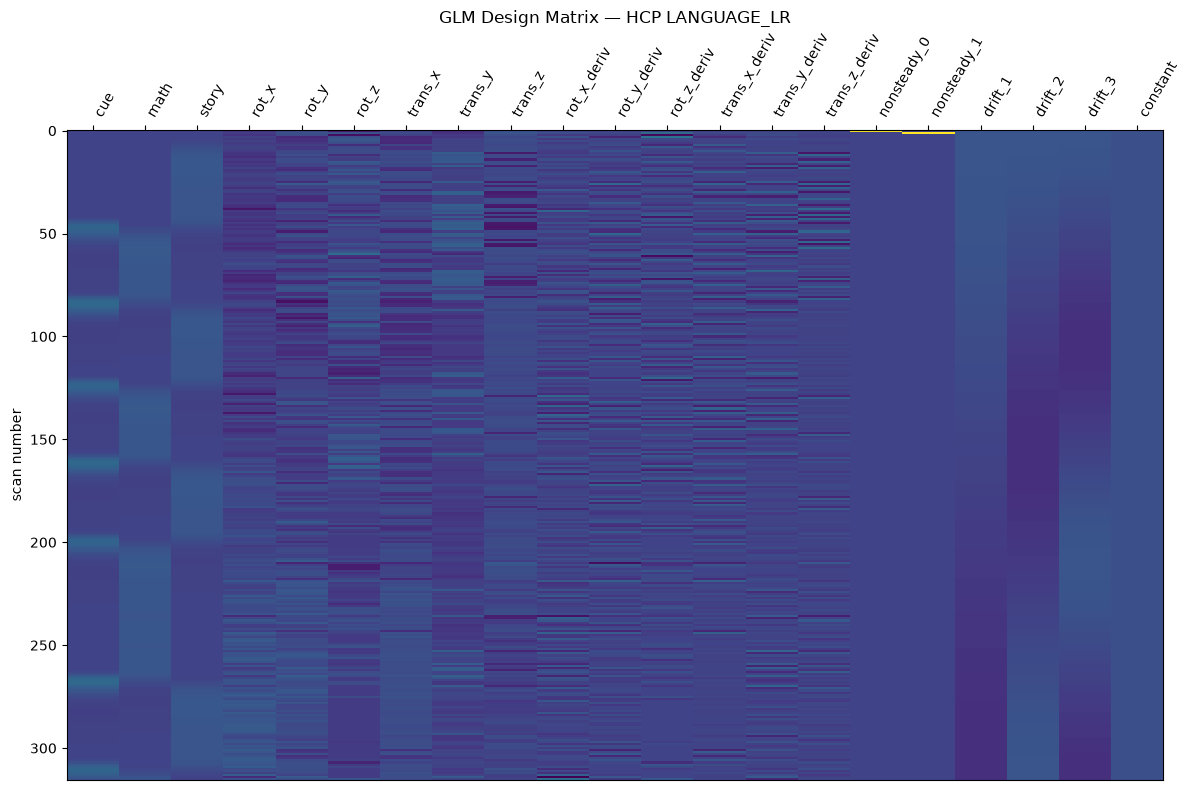

In [9]:
from nilearn.plotting import plot_design_matrix

fig, ax = plt.subplots(figsize=(12, 8))

plot_design_matrix(design_matrix, ax=ax)

ax.set_title("GLM Design Matrix — HCP LANGUAGE_LR")

plt.tight_layout()

# Save the figure for the report
fig.savefig(
    GLM_DIR / "fig_design_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2. Regressor Correlation Analysis (3b)

The design matrix has full column rank, but this does not guarantee that the regressors are independent or weakly correlated.

In the HCP Language paradigm, the story and math blocks alternate with very little implicit baseline. Their task regressors may therefore be strongly negatively correlated.

We examine the correlation matrix to identify potential multicollinearity between the task regressors and the nuisance regressors. Strong correlations can make individual beta estimates less stable, even when the design matrix has full rank.

The constant regressor is excluded from this analysis because its variance is zero.

In [10]:
# Correlation matrix between non-constant regressors
regressors = design_matrix.drop(columns=["constant"])

regressor_corr = regressors.corr()

# Save correlation matrix
regressor_corr.to_csv(GLM_DIR / "regressor_correlations.csv")

print("Correlation between task regressors:\n")
print(
    regressor_corr.loc[
        ["cue", "math", "story"],
        ["cue", "math", "story"]
    ].round(3)
)

# Strongest absolute correlation among distinct regressors
abs_corr = regressor_corr.abs().copy()

# Make a writable NumPy copy (compatibility with recent pandas versions)
abs_corr_values = abs_corr.to_numpy(copy=True)
np.fill_diagonal(abs_corr_values, 0)

abs_corr = pd.DataFrame(
    abs_corr_values,
    index=regressor_corr.index,
    columns=regressor_corr.columns
)

strongest_pair = abs_corr.stack().idxmax()
strongest_corr = regressor_corr.loc[
    strongest_pair[0], strongest_pair[1]
]

print("\nStrongest regressor correlation:")
print(f"{strongest_pair[0]} vs {strongest_pair[1]}: r = {strongest_corr:.3f}")

Correlation between task regressors:

         cue   math  story
cue    1.000 -0.065 -0.115
math  -0.065  1.000 -0.941
story -0.115 -0.941  1.000

Strongest regressor correlation:
math vs story: r = -0.941


### 2.1 Correlation Matrix Visualization

We compute the Pearson correlation between every pair of regressors of the design matrix. The constant is excluded because it has zero variance.

Highly correlated regressors share variance: the GLM cannot attribute this shared variance to one regressor or the other, which inflates the variance of their betas and reduces the statistical power (collinearity).

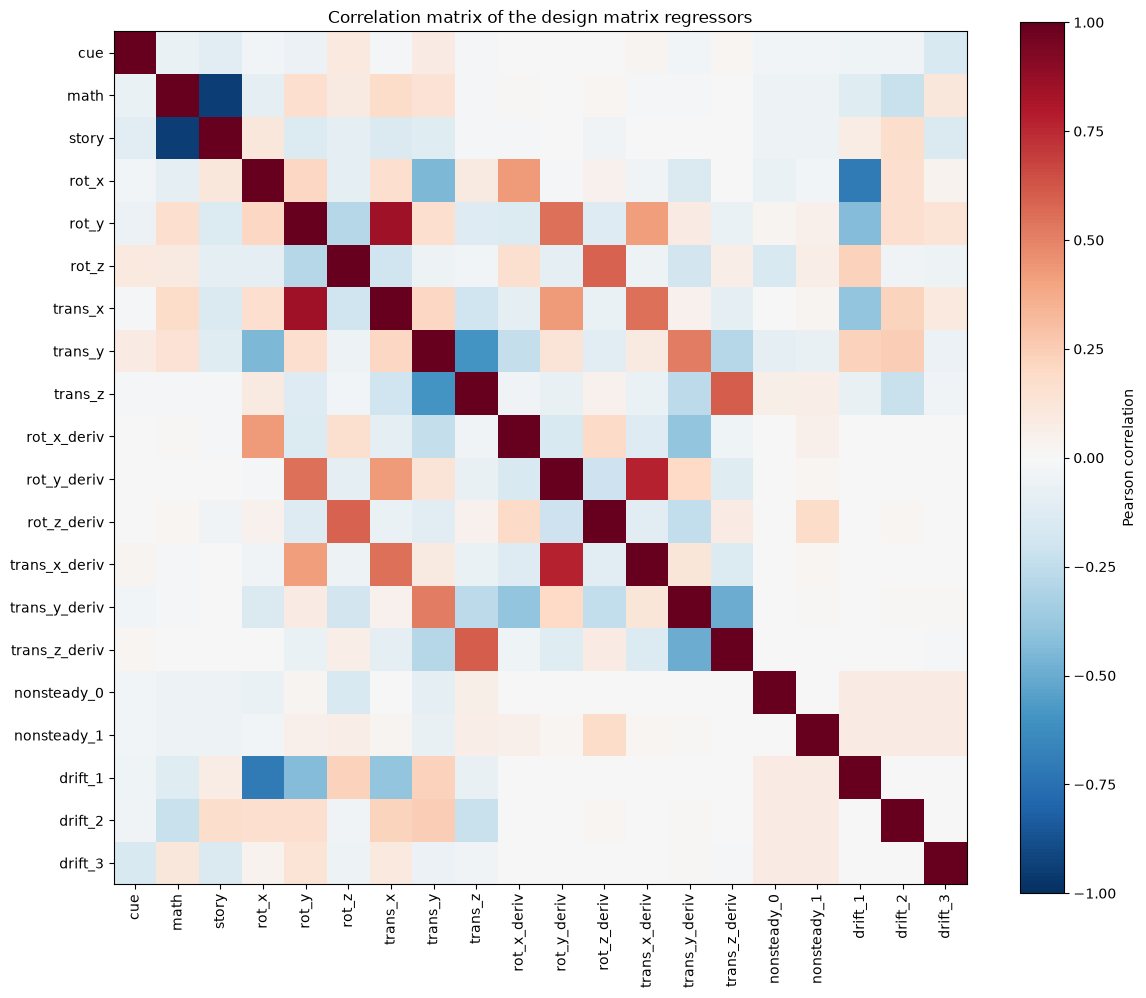

In [11]:
corr_matrix = regressor_corr

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_matrix)))
ax.set_yticks(range(len(corr_matrix)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix of the design matrix regressors")

plt.tight_layout()

# Save figure for the final report
fig.savefig(
    GLM_DIR / "fig_regressor_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.2 Interpretation of Regressor Correlations

The correlation matrix reveals a strong negative correlation between the `story` and `math` regressors (r = −0.941). This is expected because the two tasks alternate throughout the run, with only 7.3 seconds of implicit baseline.

Some motion parameters and their derivatives are also correlated, reflecting relationships between head movements and their temporal changes.

Overall, the task regressors show relatively limited correlations with most nuisance regressors. Although the design matrix has full rank, the strong anticorrelation between story and math may reduce the precision of their individual beta estimates.

The main contrast of interest, **Story − Math**, directly compares the two experimental conditions and will be examined during the first-level GLM analysis.

### 2.3 Variance Inflation Factor (VIF)

The correlation matrix only describes pairs of regressors. To quantify how well each task regressor can be estimated given **all** the other regressors (including the constant), we also compute its **variance inflation factor**:

$$
\mathrm{VIF}_j = \frac{1}{1-R_j^2}
$$

where $R_j^2$ is the coefficient of determination obtained by regressing regressor $j$ on all the other columns of the design matrix.

A VIF of 1 indicates that a regressor is orthogonal to the remaining predictors, while values above 10 are commonly considered indicative of substantial multicollinearity.

We also compute the VIF after reparameterizing the story and math regressors into their **difference (Story − Math)** and **sum (Story + Math)**.

These VIF values describe collinearity in the transformed design. They do not directly quantify the statistical significance or variance of the Story − Math contrast, which must be evaluated using the fitted GLM.

In [12]:
def variance_inflation_factor(design, column):
    # Regress one column on all the other columns of the design matrix
    y = design[column].to_numpy()
    X = design.drop(columns=column).to_numpy()
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    residuals = y - X @ beta
    r2 = 1 - residuals.var() / y.var()
    return 1 / (1 - r2)


vif = pd.Series(
    {c: variance_inflation_factor(design_matrix, c) for c in TASK_CONDITIONS},
    name="VIF"
)

# Same design, with story and math replaced by their difference and their sum
design_diff = design_matrix.copy()
design_diff["story_minus_math"] = design_matrix["story"] - design_matrix["math"]
design_diff["story_plus_math"] = design_matrix["story"] + design_matrix["math"]
design_diff = design_diff.drop(columns=["story", "math"])

print(vif.round(2).to_string())
print(f"\nVIF of (story - math): {variance_inflation_factor(design_diff, 'story_minus_math'):.2f}")
print(f"VIF of (story + math): {variance_inflation_factor(design_diff, 'story_plus_math'):.2f}")

story    20.49
math     21.66
cue       1.97

VIF of (story - math): 1.36
VIF of (story + math): 2.44


### 2.4 Interpretation of VIF Results

The variance inflation factors confirm the strong collinearity between the story and math regressors:

- **Story:** VIF = 20.49
- **Math:** VIF = 21.66
- **Cue:** VIF = 1.97

The individual story and math regressors have VIF values above 10, reflecting their strong anticorrelation (r = −0.941) and the very limited implicit baseline.

After reparameterizing the design using the sum and difference of the two task regressors, the VIF for **Story − Math is 1.36**, while the VIF for **Story + Math is 2.44**.

The relatively low VIF of the reparameterized Story − Math direction suggests that this direction has limited collinearity with the remaining predictors in the transformed design.

However, this does not directly establish the statistical precision or significance of the Story − Math contrast. These properties are assessed through the estimated contrast variance and its associated statistical test.

The **Story − Math contrast** remains particularly relevant for investigating brain activity associated with story comprehension relative to mathematical processing.

The design matrix is full rank (21/21) and ready for first-level GLM estimation.


## 3. First-Level GLM (3c)

The model uses the explicit design matrix from tasks 3a and 3b, so the event timing, SPM HRF convolution, high-pass cosine terms, motion regressors, and spike regressors are carried into the GLM.

The image is already smoothed by the functional preprocessing pipeline, so no additional smoothing will be applied during model fitting.

The first-level GLM is fitted using Nilearn's `FirstLevelModel` with an autoregressive AR(1) noise model to account for temporal autocorrelation in the fMRI signal.

### 3.1 GLM Inputs and Verification

The first-level GLM is fitted to the motion-corrected and Gaussian-smoothed functional image generated in point 2b.

We reuse the design matrix constructed in points 3a–3b, containing the task regressors, motion parameters, temporal derivatives, spike regressors, cosine drifts, and constant.

Before fitting the model, we verify that:

- The functional image contains the same number of volumes as the design matrix.
- The repetition time (TR) matches the value used to construct the experimental design.
- The design matrix contains no missing or non-finite values.
- The design matrix has full column rank.

These checks ensure that the data and the experimental model are compatible before GLM estimation.

In [13]:
# Reuse the preprocessed functional image and design matrix
glm_img = fmri_img

n_volumes = glm_img.shape[3]
n_design_rows, n_regressors = design_matrix.shape

# Verify compatibility
assert len(glm_img.shape) == 4, "Functional image must be 4D."
assert n_volumes == n_design_rows, (
    f"Mismatch: {n_volumes} fMRI volumes vs {n_design_rows} design rows."
)
assert np.isfinite(design_matrix.to_numpy()).all(), (
    "Design matrix contains NaN or infinite values."
)

matrix_rank = np.linalg.matrix_rank(design_matrix.to_numpy())

assert matrix_rank == n_regressors, (
    f"Design matrix is rank deficient: {matrix_rank}/{n_regressors}."
)

print("Functional image shape:", glm_img.shape)
print(f"Repetition time (TR): {t_r:.2f} s")
print("Design matrix shape:", design_matrix.shape)
print(f"Design matrix rank: {matrix_rank}/{n_regressors}")
print("Functional image and design matrix are compatible.")

Functional image shape: (91, 109, 91, 316)
Repetition time (TR): 0.72 s
Design matrix shape: (316, 21)
Design matrix rank: 21/21
Functional image and design matrix are compatible.


### 3.2 EPI Brain Mask

Before fitting the first-level GLM, we compute an EPI brain mask from the preprocessed functional image using Nilearn's `compute_epi_mask`.

The mask identifies voxels belonging to the brain and excludes background regions from the statistical analysis.

The resulting mask is saved as a NIfTI image and visually inspected to verify its spatial coverage before GLM estimation.

EPI brain mask saved to: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/glm/first_level/epi_brain_mask.nii.gz
Mask shape: (91, 109, 91)
Brain voxels: 207772


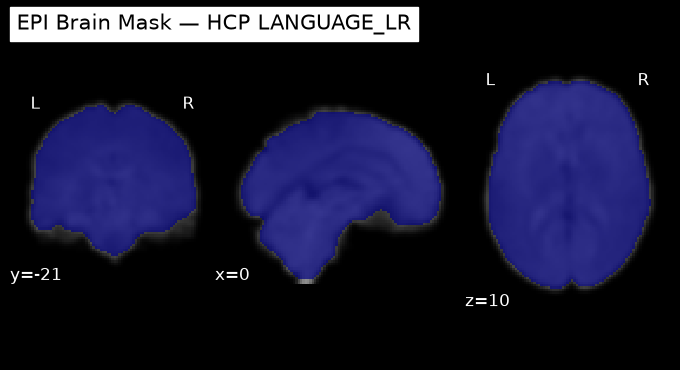

In [14]:
# Compute an EPI brain mask
epi_mask_img = compute_epi_mask(glm_img)

# Save the mask
epi_mask_path = FIRST_LEVEL_DIR / "epi_brain_mask.nii.gz"
epi_mask_img.to_filename(str(epi_mask_path))

print("EPI brain mask saved to:", epi_mask_path)
print("Mask shape:", epi_mask_img.shape)
print("Brain voxels:", int(np.count_nonzero(epi_mask_img.get_fdata())))

# Visualize the mask over the mean functional image
mean_glm_img = image.mean_img(glm_img)

display_mask = plotting.plot_roi(
    epi_mask_img,
    bg_img=mean_glm_img,
    title="EPI Brain Mask — HCP LANGUAGE_LR",
    display_mode="ortho",
    draw_cross=False
)

display_mask.savefig(str(GLM_DIR / "fig_epi_brain_mask.png"))
plotting.show()

### 3.3 First-Level GLM Fitting

We fit a first-level General Linear Model using Nilearn's `FirstLevelModel`.

The model uses the preprocessed functional image, the explicit design matrix constructed in Sections 1–2, and the EPI brain mask computed above.

An autoregressive noise model of order one (AR(1)) is used to account for temporal autocorrelation in the BOLD signal.

Since Gaussian smoothing (6 mm FWHM) was already performed during functional preprocessing, no additional spatial smoothing is applied.

The fitted model will be used to compute statistical contrasts between the experimental conditions.

In [15]:
# First-level GLM estimation
first_level_model = FirstLevelModel(
    t_r=t_r,
    noise_model="ar1",
    mask_img=epi_mask_img,
    smoothing_fwhm=None,
    standardize=False,
    signal_scaling=False,
    minimize_memory=False
)

first_level_model = first_level_model.fit(
    glm_img,
    design_matrices=design_matrix
)

print("First-level GLM fitted successfully.")
print("Noise model:", first_level_model.noise_model)
print("Number of design matrices:", len(first_level_model.design_matrices_))
print("Regressors:", len(first_level_model.design_matrices_[0].columns))

First-level GLM fitted successfully.
Noise model: ar1
Number of design matrices: 1
Regressors: 21


### 3.4 Task-Regressor Statistical Maps

For each task regressor, the contrast tests its coefficient against zero while accounting for the other regressors in the design matrix. Maps are saved unthresholded first so that effect estimates and statistics remain available regardless of display threshold.

Calculates five output maps for each condition using `compute_contrast()`:

- **effect_size:** estimated effect (beta contrast).
- **effect_variance:** estimated variance of that effect.
- **stat:** statistical test statistic for the contrast.
- **z_score:** the statistic expressed as a Z-score.
- **p_value:** the associated p-value map.

In [16]:
# Task regressors to analyze
required_task_columns = ["story", "math", "cue"]

# Save effect estimates and statistical maps for each task regressor.
task_map_paths = {}
task_contrasts = {}

for condition in required_task_columns:
    contrast_vector = np.zeros(len(design_matrix.columns), dtype=float)
    contrast_vector[design_matrix.columns.get_loc(condition)] = 1.0
    task_contrasts[condition] = contrast_vector

    condition_dir = FIRST_LEVEL_DIR / condition
    condition_dir.mkdir(parents=True, exist_ok=True)

    outputs = {
        "effect_size": first_level_model.compute_contrast(contrast_vector, output_type="effect_size"),
        "effect_variance": first_level_model.compute_contrast(contrast_vector, output_type="effect_variance"),
        "stat": first_level_model.compute_contrast(contrast_vector, output_type="stat"),
        "z_score": first_level_model.compute_contrast(contrast_vector, output_type="z_score"),
        "p_value": first_level_model.compute_contrast(contrast_vector, output_type="p_value"),
    }

    task_map_paths[condition] = {}
    for output_type, stat_img in outputs.items():
        out_path = condition_dir / f"{condition}_{output_type}.nii.gz"
        stat_img.to_filename(str(out_path))
        task_map_paths[condition][output_type] = out_path

    print(f"{condition}:")
    for output_type, out_path in task_map_paths[condition].items():
        print(f"  {output_type}: {out_path.relative_to(PROJECT_ROOT)}")

# Saves task contrast vectors as a table.
task_vector_df = pd.DataFrame(task_contrasts, index=design_matrix.columns)
task_vector_df.to_csv(FIRST_LEVEL_DIR / "task_contrast_vectors.csv")
task_vector_df

story:
  effect_size: outputs/glm/first_level/story/story_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/story/story_effect_variance.nii.gz
  stat: outputs/glm/first_level/story/story_stat.nii.gz
  z_score: outputs/glm/first_level/story/story_z_score.nii.gz
  p_value: outputs/glm/first_level/story/story_p_value.nii.gz
math:
  effect_size: outputs/glm/first_level/math/math_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/math/math_effect_variance.nii.gz
  stat: outputs/glm/first_level/math/math_stat.nii.gz
  z_score: outputs/glm/first_level/math/math_z_score.nii.gz
  p_value: outputs/glm/first_level/math/math_p_value.nii.gz
cue:
  effect_size: outputs/glm/first_level/cue/cue_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/cue/cue_effect_variance.nii.gz
  stat: outputs/glm/first_level/cue/cue_stat.nii.gz
  z_score: outputs/glm/first_level/cue/cue_z_score.nii.gz
  p_value: outputs/glm/first_level/cue/cue_p_value.nii.gz


,story,math,cue
cue,0.0,0.0,1.0
math,0.0,1.0,0.0
story,1.0,0.0,0.0
rot_x,0.0,0.0,0.0
rot_y,0.0,0.0,0.0
rot_z,0.0,0.0,0.0
trans_x,0.0,0.0,0.0
trans_y,0.0,0.0,0.0
trans_z,0.0,0.0,0.0
rot_x_deriv,0.0,0.0,0.0


### 3.5 Visualization of Task Statistical Maps

The first-level GLM produces statistical maps for the story, math, and cue conditions.

We visualize the unthresholded Z-score maps using Nilearn to inspect the spatial distribution of positive and negative effects before applying statistical thresholding.

These maps are exploratory visualizations. Statistical significance will be assessed separately using multiple-comparison correction.

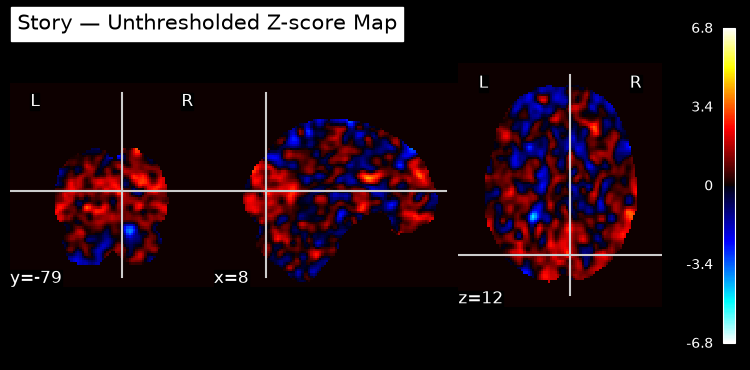

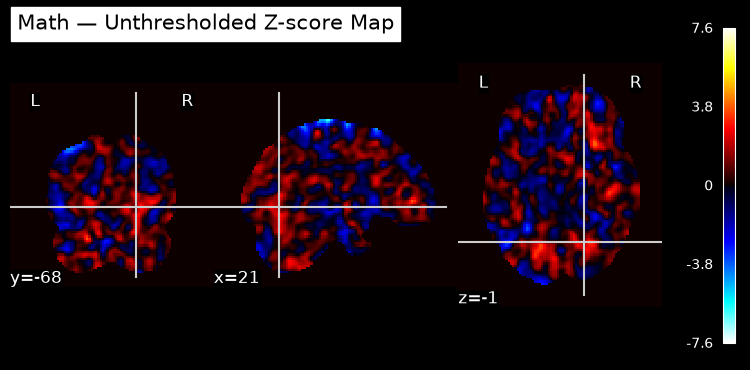

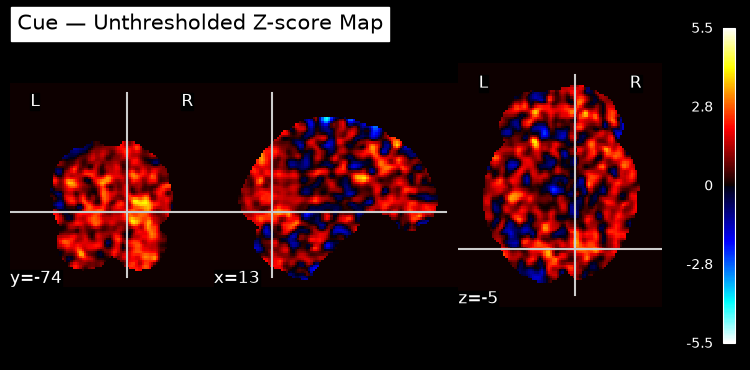

In [17]:
# Visualize unthresholded task Z-score maps
for condition in required_task_columns:
    z_map_path = task_map_paths[condition]["z_score"]

    z_map_img = nib.load(str(z_map_path))

    display_map = plotting.plot_stat_map(
        z_map_img,
        bg_img=mean_glm_img,
        title=f"{condition.capitalize()} — Unthresholded Z-score Map",
        display_mode="ortho",
        colorbar=True,
        threshold=None,
        cmap="cold_hot"
    )

    # Save figure for the report
    display_map.savefig(
        str(GLM_DIR / f"fig_{condition}_z_map_unthresholded.png")
    )

    plotting.show()

### 3.6 Multiple-Comparison Correction (FDR)

Statistical inference in fMRI involves testing a large number of voxels simultaneously. Without correction, many voxels may appear significant simply by chance.

We apply the **False Discovery Rate (FDR)** correction to the Z-score maps using Nilearn's `threshold_stats_img`, with a significance level of α = 0.05.

The FDR procedure controls the expected proportion of false discoveries among the voxels declared significant, under the assumptions of the correction procedure.

Because the story and math regressors are strongly anticorrelated, the individual condition maps should be interpreted cautiously. The direct Story − Math contrast will be analyzed separately.

Story — FDR threshold: 4.029


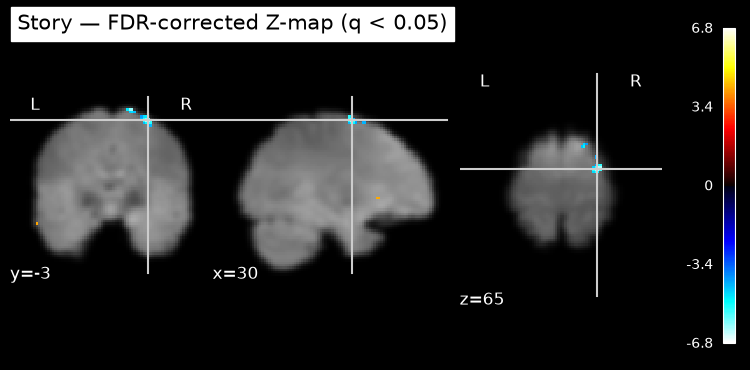

Math — FDR threshold: 3.854


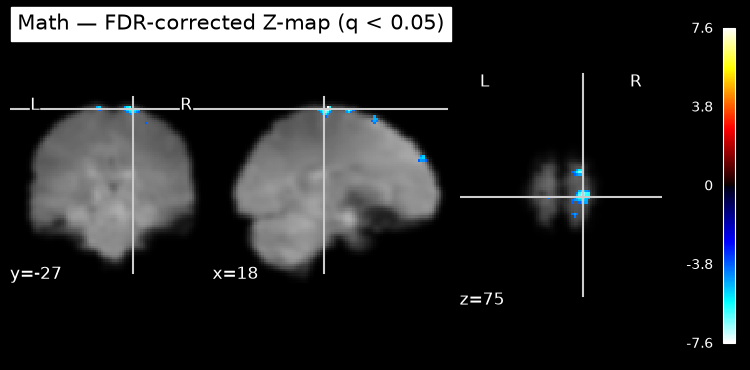

Cue — FDR threshold: 4.103


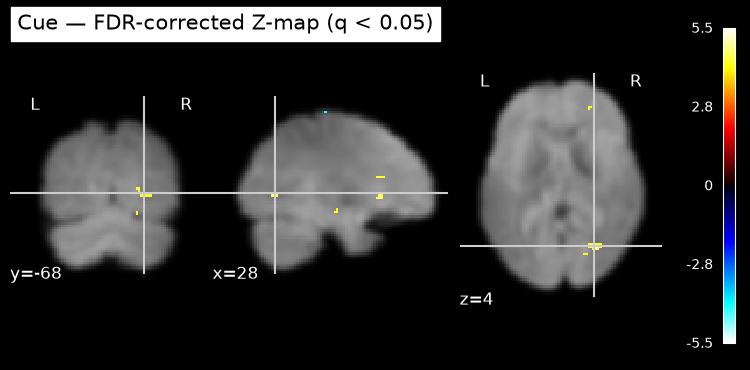

In [18]:
FDR_ALPHA = 0.05

for condition in required_task_columns:
    z_map_img = nib.load(str(task_map_paths[condition]["z_score"]))

    thresholded_img, fdr_threshold = threshold_stats_img(
        z_map_img,
        alpha=FDR_ALPHA,
        height_control="fdr",
        cluster_threshold=0,
        two_sided=True
    )

    # Save thresholded statistical map
    thresholded_path = (
        FIRST_LEVEL_DIR / condition / f"{condition}_z_score_fdr05.nii.gz"
    )
    thresholded_img.to_filename(str(thresholded_path))

    print(f"{condition.capitalize()} — FDR threshold: {fdr_threshold:.3f}")

    # Plot corrected map
    display_fdr = plotting.plot_stat_map(
        thresholded_img,
        bg_img=mean_glm_img,
        title=f"{condition.capitalize()} — FDR-corrected Z-map (q < 0.05)",
        display_mode="ortho",
        threshold=1e-6,
        colorbar=True,
        cmap="cold_hot"
    )

    display_fdr.savefig(
        str(GLM_DIR / f"fig_{condition}_z_map_fdr05.png")
    )

    plotting.show()

### 3.7 Task Statistical Maps — Results

The unthresholded Z-maps of the individual task regressors (story, math and cue, each tested against the implicit baseline) are noisy and spatially scattered, and very few voxels survive FDR correction: for story and math, only small clusters near the vertex (at the edge of the brain mask) remain, which are more likely edge effects than task-related activity. For the cue regressor, a few positive voxels survive in the occipital cortex, consistent with the brief sensory event that announces each block, but the effect is weak since it only contains 7 short events.

This lack of power is expected from the design analysis (section 2): the implicit baseline only covers 7.3 s of the run, and the story and math regressors are strongly anticorrelated (r = −0.94, VIF > 20). Each of these regressors is therefore compared with a baseline that is barely sampled, and its beta is estimated with a very large variance. The individual task maps should therefore be interpreted cautiously. The analysis focuses on the direct Story − Math contrast, which provides a meaningful comparison between the two experimental conditions. The relatively low VIF of the reparameterized difference regressor (1.36) is encouraging, but the precision and statistical significance of the contrast must be assessed using its estimated variance and statistical maps.

## 4. Statistical Contrasts (3d)

### 4.1 Story vs Math Contrast

The main objective of the HCP Language task analysis is to compare brain activity during story comprehension and mathematical processing.

Because the two experimental conditions alternate throughout the run and share very little implicit baseline, the direct **Story − Math** contrast is particularly relevant.

The contrast is defined by assigning a weight of +1 to the `story` regressor and −1 to the `math` regressor, while assigning zero weights to all nuisance regressors.

A positive contrast value indicates a stronger estimated BOLD response for Story than Math, whereas a negative value indicates a stronger estimated response for Math than Story.

We also evaluate the reverse contrast, **Math − Story**, to identify regions exhibiting the opposite pattern.

The resulting statistical maps will be visualized and corrected for multiple comparisons using FDR at q < 0.05.

In [19]:
from IPython.display import display as ipy_display

# Define contrast vectors using the design matrix column order
contrast_story_minus_math = np.zeros(len(design_matrix.columns))
contrast_math_minus_story = np.zeros(len(design_matrix.columns))

story_idx = design_matrix.columns.get_loc("story")
math_idx = design_matrix.columns.get_loc("math")

# Story > Math
contrast_story_minus_math[story_idx] = 1.0
contrast_story_minus_math[math_idx] = -1.0

# Math > Story
contrast_math_minus_story[story_idx] = -1.0
contrast_math_minus_story[math_idx] = 1.0

# Display and save the contrast vectors
contrast_vector_table = pd.DataFrame({
    "weight_story_minus_math": contrast_story_minus_math,
    "weight_math_minus_story": contrast_math_minus_story
}, index=design_matrix.columns)

contrast_vector_table.to_csv(
    FIRST_LEVEL_DIR / "story_math_contrast_vectors.csv"
)

print("Non-zero weights for Story - Math:")
ipy_display(
    contrast_vector_table[
        contrast_vector_table["weight_story_minus_math"] != 0
    ]
)

print("\nNon-zero weights for Math - Story:")
ipy_display(
    contrast_vector_table[
        contrast_vector_table["weight_math_minus_story"] != 0
    ]
)

Non-zero weights for Story - Math:


,weight_story_minus_math,weight_math_minus_story
math,-1.0,1.0
story,1.0,-1.0



Non-zero weights for Math - Story:


,weight_story_minus_math,weight_math_minus_story
math,-1.0,1.0
story,1.0,-1.0


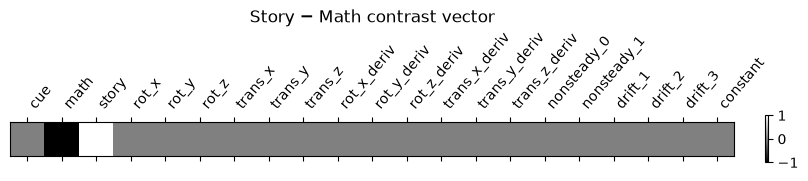

In [20]:
from nilearn.plotting import plot_contrast_matrix

ax_contrast = plot_contrast_matrix(
    contrast_story_minus_math,
    design_matrix=design_matrix,
    colorbar=True
)
ax_contrast.set_title("Story − Math contrast vector")
ax_contrast.get_figure().savefig(
    GLM_DIR / "fig_contrast_vector_story_minus_math.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

### 4.2 Contrast Estimation

We use the fitted first-level GLM to evaluate the Story − Math and Math − Story contrasts.

For each contrast, Nilearn's `compute_contrast()` is used to generate five statistical maps: effect size, effect variance, test statistic, Z-score, and p-value.

The unthresholded maps are saved as NIfTI files to preserve the complete statistical results. Multiple-comparison correction and visualization are performed in the following sections.

In [21]:
# Define the two contrasts
contrast_definitions = {
    "story_minus_math": contrast_story_minus_math,
    "math_minus_story": contrast_math_minus_story
}

contrast_map_paths = {}

for contrast_name, contrast_vector in contrast_definitions.items():

    contrast_dir = FIRST_LEVEL_DIR / contrast_name
    contrast_dir.mkdir(parents=True, exist_ok=True)

    contrast_map_paths[contrast_name] = {}

    for output_type in [
        "effect_size",
        "effect_variance",
        "stat",
        "z_score",
        "p_value"
    ]:
        stat_img = first_level_model.compute_contrast(
            contrast_vector,
            output_type=output_type
        )

        output_path = contrast_dir / f"{contrast_name}_{output_type}.nii.gz"
        stat_img.to_filename(str(output_path))

        contrast_map_paths[contrast_name][output_type] = output_path

    print(f"{contrast_name}:")
    for output_type, path in contrast_map_paths[contrast_name].items():
        print(f"  {output_type}: {path.relative_to(PROJECT_ROOT)}")

story_minus_math:
  effect_size: outputs/glm/first_level/story_minus_math/story_minus_math_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/story_minus_math/story_minus_math_effect_variance.nii.gz
  stat: outputs/glm/first_level/story_minus_math/story_minus_math_stat.nii.gz
  z_score: outputs/glm/first_level/story_minus_math/story_minus_math_z_score.nii.gz
  p_value: outputs/glm/first_level/story_minus_math/story_minus_math_p_value.nii.gz
math_minus_story:
  effect_size: outputs/glm/first_level/math_minus_story/math_minus_story_effect_size.nii.gz
  effect_variance: outputs/glm/first_level/math_minus_story/math_minus_story_effect_variance.nii.gz
  stat: outputs/glm/first_level/math_minus_story/math_minus_story_stat.nii.gz
  z_score: outputs/glm/first_level/math_minus_story/math_minus_story_z_score.nii.gz
  p_value: outputs/glm/first_level/math_minus_story/math_minus_story_p_value.nii.gz


### 4.3 Contrast Z-score Visualization

We visualize the unthresholded Z-score maps for the Story − Math and Math − Story contrasts.

Positive values in the Story − Math map indicate a stronger estimated BOLD response during story comprehension than during mathematical processing. Negative values indicate the opposite pattern.

The reverse contrast, Math − Story, should produce the same statistical pattern with opposite signs.

These maps are inspected before applying multiple-comparison correction. They are exploratory and should not yet be interpreted as statistically significant activation maps.

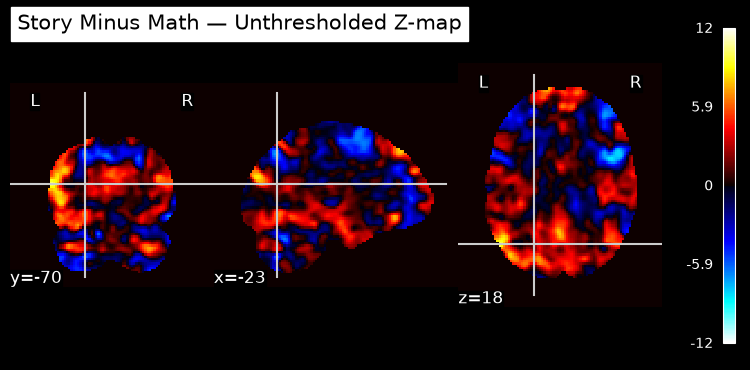

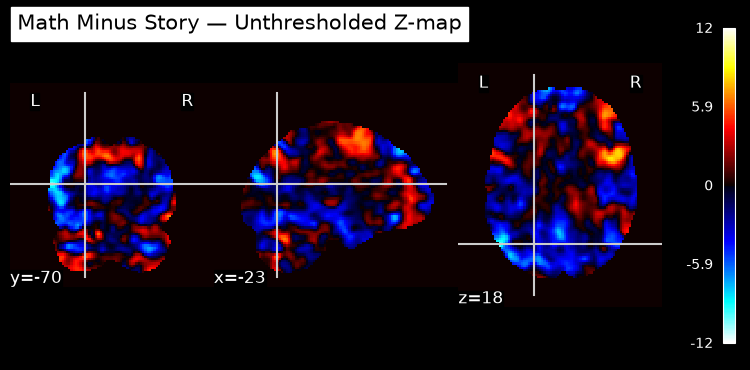

In [22]:
# Visualize unthresholded contrast Z-score maps
for contrast_name in ["story_minus_math", "math_minus_story"]:

    z_map_path = contrast_map_paths[contrast_name]["z_score"]
    z_map_img = nib.load(str(z_map_path))

    display_contrast = plotting.plot_stat_map(
        z_map_img,
        bg_img=mean_glm_img,
        title=f"{contrast_name.replace('_', ' ').title()} — Unthresholded Z-map",
        display_mode="ortho",
        threshold=None,
        colorbar=True,
        cmap="cold_hot"
    )

    # Save figure for the final report
    display_contrast.savefig(
        str(GLM_DIR / f"fig_{contrast_name}_z_map_unthresholded.png")
    )

    plotting.show()

### 4.4 FDR-Corrected Statistical Contrasts

To identify statistically significant differences between story comprehension and mathematical processing, we apply False Discovery Rate (FDR) correction to the contrast Z-score maps.

We use `threshold_stats_img` with a significance level of α = 0.05, applying a two-sided correction to retain both positive and negative significant effects.

For the Story − Math contrast, positive Z-scores indicate stronger activity during story comprehension, whereas negative Z-scores indicate stronger activity during mathematical processing.

Both corrected statistical maps are saved as NIfTI files and visualized for interpretation.


story_minus_math
FDR Z-threshold: 2.347
Significant positive voxels: 55622
Significant negative voxels: 22992


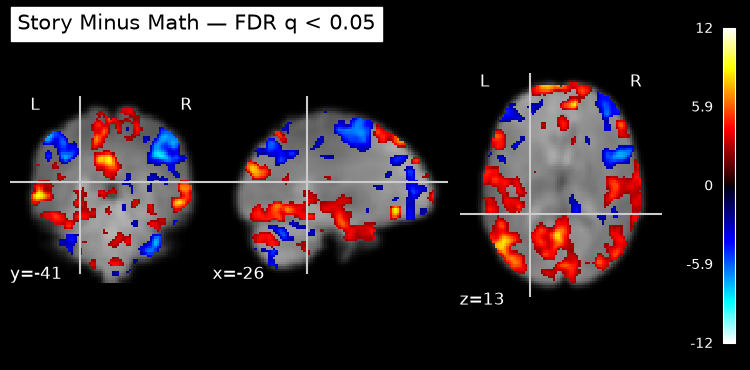


math_minus_story
FDR Z-threshold: 2.347
Significant positive voxels: 22992
Significant negative voxels: 55622


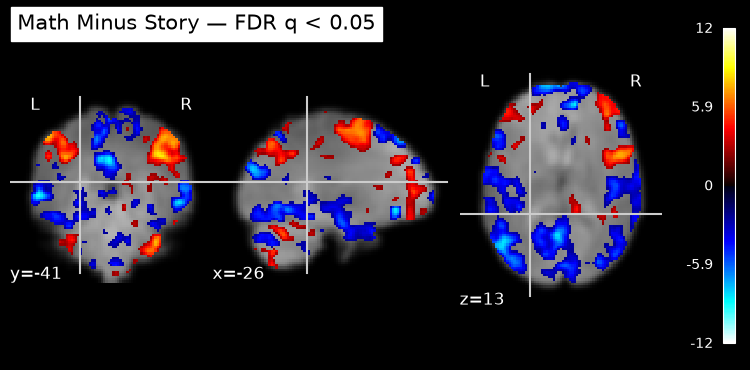

In [23]:
# FDR correction for the two opposing contrasts
contrast_fdr_results = {}

for contrast_name in ["story_minus_math", "math_minus_story"]:

    z_map_img = nib.load(
        str(contrast_map_paths[contrast_name]["z_score"])
    )

    thresholded_img, fdr_threshold = threshold_stats_img(
        z_map_img,
        alpha=FDR_ALPHA,
        height_control="fdr",
        cluster_threshold=0,
        two_sided=True
    )

    # Save corrected NIfTI map
    fdr_map_path = (
        FIRST_LEVEL_DIR / contrast_name /
        f"{contrast_name}_z_score_fdr05.nii.gz"
    )
    thresholded_img.to_filename(str(fdr_map_path))

    # Count significant positive and negative voxels
    z_data = thresholded_img.get_fdata()
    n_positive = int(np.count_nonzero(z_data > 0))
    n_negative = int(np.count_nonzero(z_data < 0))

    contrast_fdr_results[contrast_name] = {
        "threshold": fdr_threshold,
        "positive_voxels": n_positive,
        "negative_voxels": n_negative
    }

    print(f"\n{contrast_name}")
    print(f"FDR Z-threshold: {fdr_threshold:.3f}")
    print(f"Significant positive voxels: {n_positive}")
    print(f"Significant negative voxels: {n_negative}")

    # Plot and save corrected map
    display_fdr_contrast = plotting.plot_stat_map(
        thresholded_img,
        bg_img=mean_glm_img,
        title=f"{contrast_name.replace('_', ' ').title()} — FDR q < 0.05",
        display_mode="ortho",
        threshold=1e-6,
        colorbar=True,
        cmap="cold_hot"
    )

    display_fdr_contrast.savefig(
        str(GLM_DIR / f"fig_{contrast_name}_z_map_fdr05.png")
    )

    plotting.show()

# Save FDR summary
fdr_summary = pd.DataFrame.from_dict(
    contrast_fdr_results, orient="index"
)
fdr_summary.to_csv(GLM_DIR / "contrast_fdr_summary.csv")

### 4.5 Interpretation of FDR-Corrected Contrasts

The Story − Math contrast was evaluated with a two-sided FDR correction at q = 0.05 (Z-threshold = 2.347). A total of 78,614 voxels survived the correction: **55,622 positive voxels** (Story > Math) and **22,992 negative voxels** (Math > Story). The reverse contrast (Math − Story) gives exactly the opposite map, as expected.

The extent of the significant effects is large (about 38 % of the brain mask). This reflects the high efficiency of the Story − Math contrast (VIF = 1.36) and the strong difference between the two tasks, but also the liberal nature of a voxel-wise FDR threshold on spatially smoothed data: the map must therefore be interpreted at the level of its main clusters and peaks rather than voxel by voxel.

- **Story > Math:** the strongest peaks are located in the left anterior superior temporal gyrus (−54, −4, −10), the medial and lateral prefrontal cortex (frontal pole), and the posterior cerebellum (Crus I/II, mainly right). These regions correspond to the classical semantic language network and to the default-mode network.
- **Math > Story:** the peaks are located in the bilateral middle frontal gyrus, the bilateral posterior supramarginal gyrus / intraparietal region, the precuneus and the right cerebellum (Crus I). These regions correspond to the frontoparietal network classically engaged by arithmetic and numerical processing.

These results are from a single-subject, single-run analysis and should not be interpreted as population-level findings.

### 4.6 Anatomical Localization and Cluster Analysis

To interpret the Story − Math contrast, we examine the spatial distribution of significant voxels after FDR correction (q < 0.05).

We identify clusters of voxels showing stronger responses during story comprehension (positive Z-scores) and mathematical processing (negative Z-scores).

For each cluster, we extract its size, peak Z-score, and peak coordinates in MNI space.

This analysis helps characterize the spatial organization of the contrast and identify potential artifacts, particularly near the brain boundaries.

Since this is a single-subject first-level analysis, anatomical interpretations remain descriptive and do not support population-level conclusions.

In [24]:
import xml.etree.ElementTree as ET
from nilearn.reporting import get_clusters_table
from IPython.display import display as ipy_display

# Atlases distributed with FSL (MNI152 2 mm, same grid as our fMRI)
FSL_ATLAS_DIR = Path(os.environ["FSLDIR"]) / "data" / "atlases"

def load_fsl_atlas(img_rel, xml_rel):
    img = nib.load(str(FSL_ATLAS_DIR / img_rel))
    root = ET.parse(FSL_ATLAS_DIR / xml_rel).getroot()
    labels = {int(l.get("index")) + 1: l.text.strip() for l in root.find("data").findall("label")}
    return img, np.rint(img.get_fdata()).astype(int), labels

ho_img, ho_data, ho_labels = load_fsl_atlas(
    "HarvardOxford/HarvardOxford-cort-maxprob-thr25-2mm.nii.gz", "HarvardOxford-Cortical.xml")
cb_img, cb_data, cb_labels = load_fsl_atlas(
    "Cerebellum/Cerebellum-MNIfnirt-maxprob-thr25-2mm.nii.gz", "Cerebellum_MNIfnirt.xml")

def atlas_label(x, y, z):
    """Harvard-Oxford cortical or cerebellar label at an MNI coordinate."""
    for img, data, labels in [
        (ho_img, ho_data, ho_labels),
        (cb_img, cb_data, cb_labels)
    ]:
        i, j, k = np.rint(
            nib.affines.apply_affine(
                np.linalg.inv(img.affine), [x, y, z]
            )
        ).astype(int)

        if all(0 <= v < s for v, s in zip((i, j, k), data.shape)):
            atlas_value = int(data[i, j, k])

            if atlas_value > 0:
                name = labels.get(atlas_value, "Unknown region")
                return (
                    name
                    if name.startswith(("Left", "Right", "Vermis"))
                    else f"{'L' if x < 0 else 'R'} {name}"
                )

    return "Unlabelled (white matter / outside atlas)"

# FDR-corrected Story - Math map
story_math_fdr_path = FIRST_LEVEL_DIR / "story_minus_math" / "story_minus_math_z_score_fdr05.nii.gz"
story_math_fdr_img = nib.load(str(story_math_fdr_path))

positive_clusters = get_clusters_table(story_math_fdr_img, stat_threshold=0,
                                       cluster_threshold=10, two_sided=False)
negative_map = image.math_img("-img", img=story_math_fdr_img)
negative_clusters = get_clusters_table(negative_map, stat_threshold=0,
                                       cluster_threshold=10, two_sided=False)

for table in (positive_clusters, negative_clusters):
    table["Region"] = [atlas_label(r.X, r.Y, r.Z) for r in table.itertuples()]

positive_clusters.to_csv(GLM_DIR / "story_minus_math_positive_clusters.csv", index=False)
negative_clusters.to_csv(GLM_DIR / "story_minus_math_negative_clusters.csv", index=False)

print("Story > Math — peaks:")
ipy_display(positive_clusters.head(15))
print("\nMath > Story — peaks:")
ipy_display(negative_clusters.head(15))

Story > Math — peaks:


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3),Region
0,1,-4.0,62.0,30.0,11.726366,423864,L Frontal Pole
1,1a,-18.0,40.0,48.0,10.737993,,L Frontal Pole
2,1b,-54.0,-4.0,-10.0,10.655170,,"L Superior Temporal Gyrus, anterior division"
3,1c,16.0,66.0,6.0,10.425032,,R Frontal Pole
4,2,22.0,-84.0,-46.0,10.045525,8864,Right Crus II
5,2a,38.0,-74.0,-36.0,7.216208,,Right Crus I
6,2b,34.0,-82.0,-34.0,6.771001,,Right Crus I
7,2c,18.0,-66.0,-32.0,5.156630,,Right VI
8,3,-32.0,-80.0,-32.0,7.049382,3944,Left Crus I
9,3a,-38.0,-74.0,-36.0,6.945098,,Left Crus I



Math > Story — peaks:


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3),Region
0,1,46.0,-56.0,-26.0,9.898911,11288,Right Crus I
1,1a,38.0,-42.0,-38.0,7.504160,,Right Crus I
2,1b,32.0,-42.0,-46.0,6.290129,,Right VIIIa
3,1c,54.0,-64.0,-32.0,6.148911,,Right Crus I
4,2,36.0,6.0,62.0,9.373173,89088,R Middle Frontal Gyrus
5,2a,-48.0,30.0,36.0,8.591303,,L Middle Frontal Gyrus
6,2b,46.0,6.0,18.0,8.340272,,Unlabelled (white matter / outside atlas)
7,2c,-36.0,40.0,38.0,7.524126,,L Frontal Pole
8,3,42.0,-40.0,36.0,9.099285,15424,Unlabelled (white matter / outside atlas)
9,3a,54.0,-38.0,46.0,8.215111,,"R Supramarginal Gyrus, posterior division"


### 4.7 Cluster Quality Control

The FDR-corrected Story − Math contrast contains spatially extensive clusters, including a large positive cluster with a volume of 423,864 mm³.

Before interpreting these findings anatomically, we verify that the significant voxels are contained within the EPI brain mask and examine their proximity to the mask boundaries.

This quality-control step helps identify potential edge-related artifacts and supports a more cautious interpretation of the statistical maps.

In [25]:
from scipy.ndimage import binary_erosion

# Binary EPI mask and FDR-significant voxels
brain_mask = epi_mask_img.get_fdata() > 0
z_fdr = story_math_fdr_img.get_fdata()

significant = np.isfinite(z_fdr) & (z_fdr != 0)

# Verify that significant voxels remain inside the mask
outside_mask = significant & ~brain_mask

# Identify the outermost one-voxel layer of the brain mask
inner_mask = binary_erosion(brain_mask, iterations=1)
boundary_mask = brain_mask & ~inner_mask

boundary_significant = significant & boundary_mask

print("Brain mask voxels:", np.count_nonzero(brain_mask))
print("FDR-significant voxels:", np.count_nonzero(significant))
print("Significant voxels outside mask:", np.count_nonzero(outside_mask))
print("Significant voxels at mask boundary:", np.count_nonzero(boundary_significant))

print(
    "Percentage of significant voxels at boundary:",
    f"{100 * np.count_nonzero(boundary_significant) / max(np.count_nonzero(significant), 1):.2f}%"
)

print(
    "Percentage of boundary voxels significant:",
    f"{100 * np.count_nonzero(boundary_significant) / max(np.count_nonzero(boundary_mask), 1):.2f}%"
)

Brain mask voxels: 207772
FDR-significant voxels: 78614
Significant voxels outside mask: 0
Significant voxels at mask boundary: 7336
Percentage of significant voxels at boundary: 9.33%
Percentage of boundary voxels significant: 46.06%


### 4.8 Inspection of Significant Boundary Voxels

The quality-control analysis shows that all 78,614 FDR-significant voxels are contained within the EPI brain mask.

Among these voxels, 7,336 (9.33%) are located on the outermost voxel layer of the mask. Furthermore, 46.06% of the mask boundary voxels are statistically significant.

Although these findings do not establish the presence of artifacts, they suggest that the spatial distribution of significant effects near brain boundaries deserves further inspection.

We therefore visualize the boundary-associated significant voxels to assess their anatomical distribution before drawing conclusions from the Story − Math contrast.

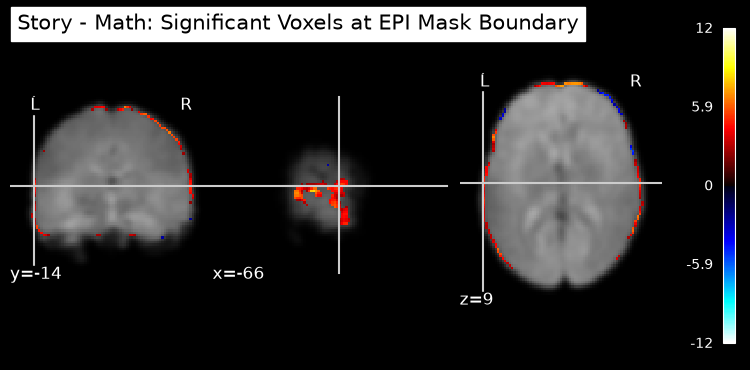

In [26]:
# Identify FDR-significant voxels located at the EPI mask boundary
boundary_z = np.where(boundary_significant, z_fdr, 0.0)

boundary_z_img = image.new_img_like(
    story_math_fdr_img,
    boundary_z
)

# Visualize boundary-associated significant effects
display_boundary = plotting.plot_stat_map(
    boundary_z_img,
    bg_img=mean_glm_img,
    title="Story - Math: Significant Voxels at EPI Mask Boundary",
    display_mode="ortho",
    cmap="cold_hot",
    colorbar=True,
    threshold=1e-6
)

# Save the QC figure
display_boundary.savefig(
    str(GLM_DIR / "fig_significant_boundary_voxels.png")
)

plotting.show()

### 4.9 Interior Brain Activation Check

The boundary inspection reveals significant voxels along parts of the EPI brain mask contour, suggesting that edge-related effects should be considered when interpreting the statistical maps.

To determine whether significant effects are also present within the brain, we perform a supplementary quality-control analysis using an eroded version of the EPI mask.

We exclude the outermost voxel layer for this diagnostic visualization and compare the number of significant voxels retained in the interior.

This procedure does not modify the fitted GLM, the original FDR correction, or the statistical contrast maps. It is used only to assess the spatial distribution of the results.

Total FDR-significant voxels: 78614
Significant voxels in brain interior: 71278
Percentage retained: 90.67%


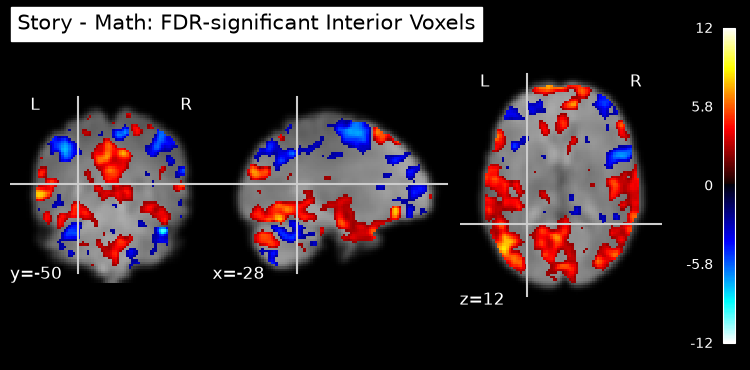

In [27]:
# Keep only significant voxels inside the eroded EPI mask
interior_significant = significant & inner_mask

n_total = int(np.count_nonzero(significant))
n_interior = int(np.count_nonzero(interior_significant))

print("Total FDR-significant voxels:", n_total)
print("Significant voxels in brain interior:", n_interior)
print(f"Percentage retained: {100 * n_interior / n_total:.2f}%")

# Create interior-only visualization (QC, not a new statistical test)
interior_z = np.where(interior_significant, z_fdr, 0.0)

interior_z_img = image.new_img_like(
    story_math_fdr_img,
    interior_z
)

display_interior = plotting.plot_stat_map(
    interior_z_img,
    bg_img=mean_glm_img,
    title="Story - Math: FDR-significant Interior Voxels",
    display_mode="ortho",
    cmap="cold_hot",
    colorbar=True,
    threshold=1e-6
)

display_interior.savefig(
    str(GLM_DIR / "fig_significant_interior_voxels.png")
)

plotting.show()

## 5. Functional Networks (3e)

To interpret the Story − Math contrast in terms of large-scale functional networks, we use the Schaefer et al. (2018) 400-parcel atlas, whose parcels are assigned to the seven functional networks described by Yeo et al. (2011): visual, somatomotor, dorsal attention, ventral attention/salience, limbic, frontoparietal control, and default mode.

For each network, we compute the percentage of its voxels that are significant for Story > Math and for Math > Story (FDR q < 0.05), and we overlay the contours of the default-mode and frontoparietal networks on the contrast map.

Parcels: 400
Yeo labels present: [0 1 2 3 4 5 6 7]


,Voxels,% Story > Math,% Math > Story,Mean Z (Story − Math)
Network,,,,
Visual,20876,48.8,3.5,2.2
Somatomotor,16593,44.8,3.3,1.9
Dorsal attention,11847,14.8,37.7,-1.2
Ventral attention / salience,13327,16.2,19.8,-0.2
Limbic,6755,42.8,1.5,2.1
Frontoparietal control,16347,9.6,35.6,-1.3
Default mode,29789,56.1,4.6,2.8


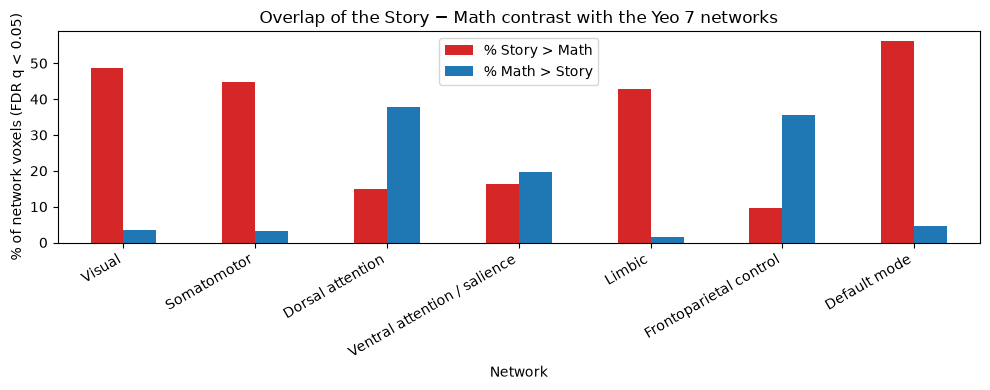

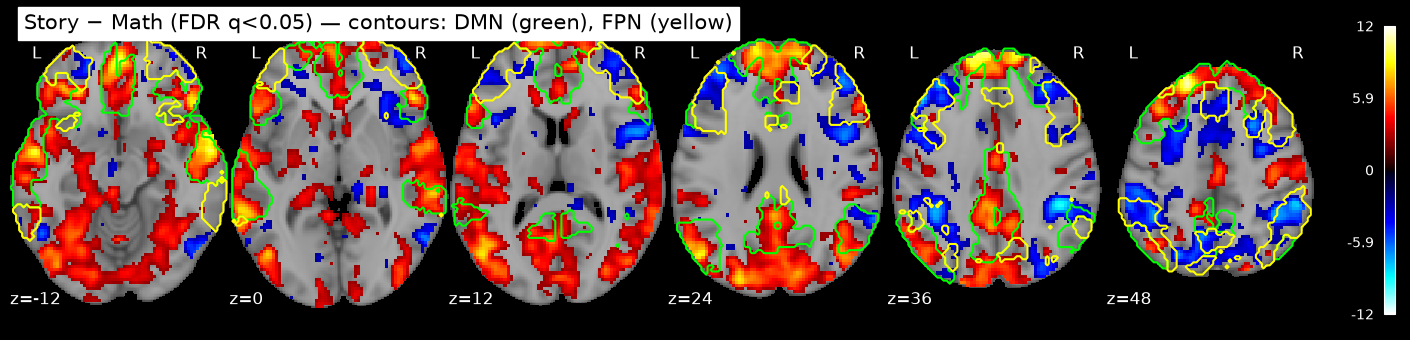

In [28]:
from nilearn import datasets

# Yeo et al. (2011) 7 networks, obtained from the Schaefer et al. (2018) atlas:
# each of the 400 parcels is assigned to one of the 7 Yeo networks (name in the label).
schaefer = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)

schaefer_img = image.load_img(schaefer.maps)
schaefer_data = np.rint(schaefer_img.get_fdata()).astype(int)
schaefer_labels = [l.decode() if isinstance(l, bytes) else str(l) for l in schaefer.labels]
schaefer_labels = [l for l in schaefer_labels if l != "Background"]  # recent Nilearn versions

# Network keyword in the Schaefer label -> Yeo network index (same order as YEO7)
NETWORK_KEYS = {"_Vis_": 1, "_SomMot_": 2, "_DorsAttn_": 3, "_SalVentAttn_": 4,
                "_Limbic_": 5, "_Cont_": 6, "_Default_": 7}

yeo_from_schaefer = np.zeros_like(schaefer_data)
for parcel_value, label in enumerate(schaefer_labels, start=1):
    network = next(v for k, v in NETWORK_KEYS.items() if k in label)
    yeo_from_schaefer[schaefer_data == parcel_value] = network

yeo_img = image.new_img_like(schaefer_img, yeo_from_schaefer.astype(np.int32))
yeo_img = image.resample_to_img(yeo_img, story_math_fdr_img, interpolation="nearest")
yeo_data = np.rint(yeo_img.get_fdata()).astype(int)

print("Parcels:", len(schaefer_labels))
print("Yeo labels present:", np.unique(yeo_data))

YEO7 = {1: "Visual", 2: "Somatomotor", 3: "Dorsal attention",
        4: "Ventral attention / salience", 5: "Limbic",
        6: "Frontoparietal control", 7: "Default mode"}

z_unthr = nib.load(str(contrast_map_paths["story_minus_math"]["z_score"])).get_fdata()
story_sig = z_fdr > 0
math_sig = z_fdr < 0

rows = []
for value, name in YEO7.items():
    net = (yeo_data == value) & brain_mask
    n = int(net.sum())
    rows.append({
        "Network": name,
        "Voxels": n,
        "% Story > Math": 100 * np.sum(story_sig & net) / n,
        "% Math > Story": 100 * np.sum(math_sig & net) / n,
        "Mean Z (Story − Math)": z_unthr[net].mean(),
    })
network_table = pd.DataFrame(rows).set_index("Network").round(1)
network_table.to_csv(GLM_DIR / "story_minus_math_yeo7_overlap.csv")
ipy_display(network_table)

# Bar plot of the overlap
fig, ax = plt.subplots(figsize=(10, 4))
network_table[["% Story > Math", "% Math > Story"]].plot.bar(
    ax=ax, color=["tab:red", "tab:blue"])
ax.set_ylabel("% of network voxels (FDR q < 0.05)")
ax.set_title("Overlap of the Story − Math contrast with the Yeo 7 networks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
fig.savefig(GLM_DIR / "fig_yeo7_overlap.png", dpi=300, bbox_inches="tight")
plt.show()

# Contrast map on the MNI template with DMN (green) and FPN (yellow) contours
mni_1mm = Path(os.environ["FSLDIR"]) / "data" / "standard" / "MNI152_T1_1mm_brain.nii.gz"
display_net = plotting.plot_stat_map(
    story_math_fdr_img, bg_img=str(mni_1mm), display_mode="z",
    cut_coords=[-12, 0, 12, 24, 36, 48], threshold=1e-6, cmap="cold_hot",
    title="Story − Math (FDR q<0.05) — contours: DMN (green), FPN (yellow)")
display_net.add_contours(image.math_img("img == 7", img=yeo_img), levels=[0.5], colors="lime")
display_net.add_contours(image.math_img("img == 6", img=yeo_img), levels=[0.5], colors="yellow")
display_net.savefig(str(GLM_DIR / "fig_story_minus_math_yeo_contours.png"))
plotting.show()

### 5.1 Functional Network Results

**Story > Math.** The largest overlap is found with the **default-mode network** (56.1 % of its voxels, mean Z = +2.8), followed by the visual (48.8 %), somatomotor (44.8 %) and limbic (42.8 %) networks. The default-mode network is known to support semantic and narrative processing (comprehension of a story, integration of meaning and of the situation model), and the limbic network includes the temporal poles and orbitofrontal cortex, which are associated with conceptual knowledge. The somatomotor network of Yeo et al. (2011) also includes the auditory cortex of the superior temporal gyrus, consistent with the continuous spoken narrative of the story condition.

**Math > Story.** The overlap is highest with the **dorsal attention network** (37.7 %) and the **frontoparietal control network** (35.6 %), followed by the ventral attention/salience network (19.8 %). These networks, centred on the intraparietal sulcus and the dorsolateral prefrontal cortex, are engaged by numerical manipulation, working memory and goal-directed attention, which are required by the arithmetic task. The mean Z of these two networks is negative (−1.2 and −1.3), confirming that they are, on average, more active during math than story.

The contour figure shows this double dissociation: Story > Math effects (red) fall mostly inside the default-mode contours (green), whereas Math > Story effects (blue) fall inside the frontoparietal contours (yellow).

**Caveats.** The large Story > Math overlap with the visual and somatomotor networks should be interpreted cautiously. It partly reflects the liberal FDR threshold and the spatial smoothing, and it may also reflect a relative deactivation of sensory cortices during the more demanding arithmetic task rather than a genuine activation during the story. Moreover, the Yeo networks were defined at rest in a group of subjects and are only an approximation of the functional organisation of this individual brain.

## 6. Semantic Language Regions (3f)

The literature on semantic language processing, and in particular the study from which this task was adapted (Binder et al. 2011), highlights a left-lateralised network including the **anterior temporal lobe** (temporal pole and anterior middle/superior temporal gyri), the **posterior middle temporal gyrus**, the **inferior frontal gyrus** (pars triangularis) and the **angular gyrus**.

We quantify the Story − Math effect in these regions using the Harvard-Oxford atlas, in both hemispheres. We also compute the mean EPI signal in each region relative to the whole brain, to detect susceptibility-related signal dropout, which typically affects the anterior and inferior temporal lobes.

In [29]:
SEMANTIC_ROIS = [
    "Temporal Pole",
    "Superior Temporal Gyrus, anterior division",
    "Middle Temporal Gyrus, anterior division",
    "Middle Temporal Gyrus, posterior division",
    "Inferior Frontal Gyrus, pars triangularis",
    "Angular Gyrus",
]
name_to_value = {v: k for k, v in ho_labels.items()}
missing = [r for r in SEMANTIC_ROIS if r not in name_to_value]
assert not missing, f"Labels not found: {missing}. Available: {list(name_to_value)}"

# Hemisphere masks from the x coordinate of each voxel
x_mm = ho_img.affine[0, 0] * np.arange(ho_data.shape[0]) + ho_img.affine[0, 3]
hemispheres = {"L": (x_mm < 0)[:, None, None], "R": (x_mm > 0)[:, None, None]}

# Mean EPI signal (unsmoothed) to detect signal dropout
mean_epi = image.mean_img(str(moco_fmri_path)).get_fdata()
brain_mean_signal = mean_epi[brain_mask].mean()

rows = []
for roi in SEMANTIC_ROIS:
    for hemi, hemi_mask in hemispheres.items():
        roi_mask = (ho_data == name_to_value[roi]) & hemi_mask & brain_mask
        n = int(roi_mask.sum())
        rows.append({
            "Region": f"{hemi} {roi}",
            "Voxels": n,
            "% Story > Math": 100 * np.sum(story_sig & roi_mask) / max(n, 1),
            "Max Z": z_unthr[roi_mask].max() if n else np.nan,
            "Mean Z": z_unthr[roi_mask].mean() if n else np.nan,
            "Relative EPI signal": mean_epi[roi_mask].mean() / brain_mean_signal if n else np.nan,
        })
semantic_table = pd.DataFrame(rows).set_index("Region").round(2)
semantic_table.to_csv(GLM_DIR / "semantic_rois_story_minus_math.csv")
ipy_display(semantic_table)

,Voxels,% Story > Math,Max Z,Mean Z,Relative EPI signal
Region,,,,,
L Temporal Pole,1806,77.35,9.23,3.66,0.98
R Temporal Pole,1888,73.09,9.52,4.19,1.03
"L Superior Temporal Gyrus, anterior division",253,99.21,10.66,6.13,1.04
"R Superior Temporal Gyrus, anterior division",268,98.51,9.84,6.11,1.09
"L Middle Temporal Gyrus, anterior division",422,90.28,9.81,5.28,0.93
"R Middle Temporal Gyrus, anterior division",371,75.20,9.55,4.37,1.01
"L Middle Temporal Gyrus, posterior division",1093,47.39,9.35,2.42,0.86
"R Middle Temporal Gyrus, posterior division",893,40.87,8.32,2.18,0.86
"L Inferior Frontal Gyrus, pars triangularis",590,60.51,7.77,2.92,1.07


### 6.1 Semantic Region Results

**Are the semantic regions present?** Yes. All the regions highlighted in the literature show a significant Story > Math effect:

- **Anterior temporal lobe:** the left anterior superior temporal gyrus (99 % of its voxels significant, max Z = 10.7), the left anterior middle temporal gyrus (90 %, max Z = 9.8) and the left temporal pole (77 %, max Z = 9.2). This is the region for which the task was originally designed (Binder et al. 2011), and it is clearly detected here.
- **Left inferior frontal gyrus (pars triangularis):** 61 % of voxels, max Z = 7.8.
- **Left posterior middle temporal gyrus:** 47 %, max Z = 9.4.
- **Left angular gyrus:** 43 %, max Z = 6.8.

The relative EPI signal in the temporal poles is close to the whole-brain average (0.98 left, 1.03 right), which shows that susceptibility-related signal dropout did not remove these regions in this dataset.

**Differences with the expected pattern.** Two aspects are weaker than expected from the literature:

1. **Lateralisation.** Semantic language processing is expected to be left-lateralised, but the effects are largely bilateral (for instance, 73 % of the right temporal pole and 71 % of the right IFG are significant). The story condition also engages processes that are bilateral, such as prosody, narrative integration and social cognition (theory of mind), and spatial smoothing (6 mm) and the liberal FDR threshold further spread the effects across hemispheres.
2. **Angular gyrus.** The angular gyrus shows the weakest effect (43 % on the left, only 12 % and a negative mean Z on the right). The angular gyrus is involved in semantic integration but also in arithmetic, in particular in the retrieval of arithmetic facts, so it is partly active in both conditions and its activity is cancelled by the subtraction.

**Possible reasons why semantic regions can be absent or weak in such contrasts:**

- **Choice of the contrast and of the control condition.** A contrast only reveals regions that differ between the two conditions. Here, the math task is also presented auditorily with spoken words, so language regions involved in speech perception and phonological processing are active in both conditions and cancel out. Conversely, with a rest baseline, semantic regions such as the ATL and the angular gyrus are often missed because spontaneous semantic processing during rest is high (Binder et al. 2011); this is why an active, non-semantic control condition such as math is used.
- **Susceptibility artefacts.** The anterior and inferior temporal lobes lie close to the air-filled sinuses and ear canals, where EPI signal dropout and distortions are common, and the ATL is often missing in standard fMRI acquisitions. This is not the case here (relative EPI signal ≈ 1 in the temporal poles), thanks to the HCP acquisition and distortion correction.
- **Statistical power and single-subject variability.** With a single run of one subject (316 volumes, about 4 stories), weaker effects may not survive multiple-comparison correction, and individual anatomical and functional variability means that group-level coordinates do not exactly match the individual pattern.

## 7. Final Outputs and Verification

The first-level GLM analysis has been completed using the preprocessed HCP LANGUAGE_LR functional run and the experimental design matrix.

The analysis includes:

- Construction of the experimental design matrix with task, motion, spike, and drift regressors.
- Assessment of regressor correlations and variance inflation factors.
- First-level GLM estimation using an AR(1) noise model.
- Computation of individual task statistical maps and the Story − Math / Math − Story contrasts.
- False Discovery Rate (FDR) correction at q = 0.05.
- Anatomical cluster inspection and supplementary brain-mask boundary quality control.
- Overlap of the Story − Math contrast with the 7 Yeo networks (Schaefer et al. 2018 atlas).
- Quantification of the Story − Math effect in literature-based semantic regions (Harvard-Oxford atlas).

The Story − Math contrast yielded 78,614 FDR-significant voxels, of which 71,278 (90.67%) remained inside the eroded EPI mask.

The boundary and interior inspections are descriptive quality-control procedures. They do not change the fitted GLM or establish that all significant effects are free from artifacts.

The following verification checks confirm that the expected output files exist and that the principal contrast maps are spatially and statistically consistent.

In [30]:
# Final GLM output verification

required_files = [
    GLM_DIR / "design_matrix.csv",
    GLM_DIR / "glm_events.csv",
    GLM_DIR / "regressor_correlations.csv",
    GLM_DIR / "contrast_fdr_summary.csv",
    GLM_DIR / "fig_design_matrix.png",
    GLM_DIR / "fig_regressor_correlations.png",
    GLM_DIR / "fig_story_minus_math_z_map_fdr05.png",
    GLM_DIR / "fig_significant_interior_voxels.png",
    FIRST_LEVEL_DIR / "epi_brain_mask.nii.gz",
    FIRST_LEVEL_DIR / "story_math_contrast_vectors.csv",
]

# Verify the five statistical maps for each condition/contrast
map_types = [
    "effect_size",
    "effect_variance",
    "stat",
    "z_score",
    "p_value"
]

for name in [
    "story",
    "math",
    "cue",
    "story_minus_math",
    "math_minus_story"
]:
    for map_type in map_types:
        required_files.append(
            FIRST_LEVEL_DIR / name / f"{name}_{map_type}.nii.gz"
        )

    required_files.append(
        FIRST_LEVEL_DIR / name / f"{name}_z_score_fdr05.nii.gz"
    )

missing_files = [p for p in required_files if not p.is_file()]

print(f"Expected output files: {len(required_files)}")
print(f"Existing output files: {len(required_files) - len(missing_files)}")

if missing_files:
    print("\nMissing files:")
    for p in missing_files:
        print(" -", p.relative_to(PROJECT_ROOT))
else:
    print("[OK] All required GLM outputs are present.")

# Verify that opposite contrasts produce opposite Z-scores
story_z = nib.load(
    str(contrast_map_paths["story_minus_math"]["z_score"])
).get_fdata()

math_z = nib.load(
    str(contrast_map_paths["math_minus_story"]["z_score"])
).get_fdata()

max_symmetry_error = np.max(np.abs(story_z + math_z))

print(f"\nMaximum contrast Z-score symmetry error: {max_symmetry_error:.6g}")
print("Design matrix rank:", np.linalg.matrix_rank(design_matrix.to_numpy()))
print("Design matrix columns:", design_matrix.shape[1])
print("FDR-significant voxels:", n_total)
print("Interior significant voxels:", n_interior)

assert not missing_files, "Some required output files are missing."
assert np.isfinite(max_symmetry_error), "Non-finite Z-score symmetry error."
assert max_symmetry_error < 1e-4, "Opposite contrast Z-maps are not symmetric."

print("\n[OK] Final GLM verification completed successfully.")

Expected output files: 40
Existing output files: 40
[OK] All required GLM outputs are present.

Maximum contrast Z-score symmetry error: 0
Design matrix rank: 21
Design matrix columns: 21
FDR-significant voxels: 78614
Interior significant voxels: 71278

[OK] Final GLM verification completed successfully.


## 8. Conclusion

We fitted a first-level GLM to the HCP LANGUAGE_LR run with a design matrix of 316 time points and 21 regressors (story, math and cue blocks convolved with the SPM HRF; six motion parameters and their derivatives; two initial-volume spike regressors; three cosine drifts; a constant), with full column rank.

The story and math regressors are strongly anticorrelated (r = −0.94, VIF > 20), because the two tasks alternate with only 7.3 s of implicit baseline. As a consequence, the individual task maps (each condition against baseline) have little power, whereas the Story − Math contrast is estimated efficiently (VIF = 1.36) and is the main result of the analysis.

After FDR correction (q < 0.05), the Story − Math contrast reveals a distinct spatial patterns of Story > Math and Math > Story effects:

- **Story > Math** in the bilateral anterior temporal lobes (temporal pole, anterior superior and middle temporal gyri), the inferior frontal gyrus, the medial prefrontal cortex, the posterior middle temporal and angular gyri and the posterior cerebellum, overlapping mainly with the **default-mode** (56 % of its voxels) and **limbic** networks;
- **Math > Story** in the bilateral middle frontal gyrus, the supramarginal / intraparietal cortex, the precuneus and the right cerebellum, overlapping mainly with the **dorsal attention** (38 %) and **frontoparietal control** (36 %) networks.

All the semantic regions described in the literature, including the anterior temporal lobe targeted by this task (Binder et al. 2011), are detected, without signal dropout in the temporal poles. The effects are, however, more bilateral than expected, and the angular gyrus shows a weaker effect, probably because it is also engaged by arithmetic.

**Limitations:** single-subject, single-run analysis; strong correlation between the task regressors; large extent of the significant effects due to smoothing and a liberal voxel-wise FDR threshold; resting-state network atlases defined at the group level.